# ¿Lleva una respuesta la unidad de su pregunta? La compuerta de unidades sobre los documentos versionados de los casos

**Pregunta:** Cuando la respuesta de un método es correcta en su propia unidad y errónea en la unidad de la pregunta (una probabilidad escrita en porcentaje, un capital en miles, una constante de otro observable), ¿qué regla de la compuerta de unidades la ve, cuánto debe equivocarse la respuesta para que la compuerta bloquee y qué errores deja pasar la compuerta?

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** notebooks 01 a 05 de este tema
- **Tiempo de lectura:** unos 75 minutos

## Objetivos

Al terminar este notebook puedes:

- explicar por qué una compuerta que pregunta si la cadena de cálculo corrió nunca ve una respuesta en la unidad equivocada, y mostrar en las pruebas del propio motor qué errores una prueba ya rechaza y cuáles informa como un mal modelo;
- escribir como ecuación el rango ensanchado de los cuatro tipos de objetivo (una serie, un desenlace 0/1, una verdad conocida y una cota) y calcularlo a mano sobre un documento versionado;
- leer la especificación `data-pipeline/config/unit_pairs.json`: la entrada de un caso, la ruta de una predicción y de su objetivo, el tipo, la unidad, la escala del cero y el dominio;
- correr `pipeline.stages.unit_gate` sobre documentos versionados de cuatro casos y leer el veredicto de cada par, bloqueante y de aviso;
- plantar un porcentaje, un factor de 1.000 y dos cambios de signo en una copia de un documento, y leer la clase de violación que la compuerta nombra en cada caso;
- medir desde dónde empieza a bloquear la compuerta un error multiplicativo y poner el umbral medido junto al que enuncia la regla;
- nombrar, con código, lo que la compuerta deja pasar (un error dentro del rango ensanchado, un error hacia abajo, un cero exacto, una cota que es solo un dominio, una predicción faltante) y declarar un par para un archivo propio.

## Preparación

Instala el entorno fijado una sola vez, en un entorno virtual, con el comando conocido:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 pandas==3.0.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La compuerta de unidades es un solo archivo de la cadena de cálculo del producto, `data-pipeline/pipeline/stages/unit_gate.py`, escrito solo con la biblioteca estándar para que la comprobación distribuida pueda cargarlo por ruta. La cadena de cálculo son scripts sueltos y no un paquete, así que la celda siguiente pone `data-pipeline/` en la ruta de importación e importa la etapa desde allí: una sola función para el horneado, la comprobación distribuida, las pruebas y este notebook, nunca una copia. El motor `riskvalidation` se importa solo para las pruebas del paso 2. El notebook lee archivos versionados y nunca escribe uno. La celda imprime la versión de cada paquete y las constantes que define la etapa.

In [1]:
# Poner la cadena de cálculo en la ruta de importación, importar la compuerta de unidades e imprimir las versiones
import fnmatch
import importlib.metadata as md
import json
import sys
from copy import deepcopy
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from riskvalidation.core.policy import default_policy
from riskvalidation.validation import calibration as cal, discrimination as disc

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.stages import unit_gate as gate


def read_json(relative):
    return json.loads((ROOT / relative).read_text(encoding="utf-8"))


for name in ("riskvalidation", "numpy", "pandas", "matplotlib"):
    print(name, md.version(name))
print("constantes de la regla:", "RANGE_SLACK =", gate.RANGE_SLACK, "| FLAT_REL =", gate.FLAT_REL)
print("tipos de objetivo:", gate.KINDS)
print("entradas de un caso:", gate.ENTRY_KINDS)

riskvalidation 1.1.0
numpy 2.4.6
pandas 3.0.6
matplotlib 3.11.2
constantes de la regla: RANGE_SLACK = 1.0 | FLAT_REL = 1e-06
tipos de objetivo: ('series', 'binary', 'scalar', 'bound')
entradas de un caso: ('pairs', 'bake_only', 'withheld', 'not_applicable')


## Datos

El notebook sigue una sola regla sobre documentos de cinco casos, todos versionados.

- **La especificación:** `data-pipeline/config/unit_pairs.json`, escrita para este producto. Declara, por caso construido, qué predicción se puntúa contra qué objetivo y en qué unidad.
- **C01, PD minorista (`data/derived/C01/german-twin.json`):** los datos de German Credit, Hofmann, H. (1994), Statlog (German Credit Data), UCI Machine Learning Repository, https://archive.ics.uci.edu/dataset/144/statlog+german+credit+data, clase de licencia `mirror-allowed` (CC BY 4.0). Estado de verdad `real-outcomes`: 1.000 solicitantes reales.
- **C09, exposición al incumplimiento (`data/derived/C09/level-0.json`):** generada por el generador del propio producto; estado de verdad `synthetic-known-truth`, sin datos de terceros.
- **C16, estrés inverso de liquidez (`data/derived/C16/fast-run.json`):** una corrida calibrada sobre las fuentes FDIC BankFind, el informe H.8 de la Reserva Federal, la revisión de la Reserva Federal sobre Silicon Valley Bank (2023-04-28) y la curva par del Tesoro, todas de clase de licencia `mirror-allowed`; estado de verdad `synthetic-calibrated`.
- **C17, capital de riesgo operacional (`data/derived/C17/xi-0-8.json`) y C05, carteras de bajo incumplimiento (`data/derived/C05/ldp-sim-1.json`):** generados por los generadores del propio producto, estado de verdad `synthetic-known-truth`.
- **Documentos versionados que se leen** (rutas desde la raíz del repositorio): la especificación y los cinco documentos anteriores. No se lee nada más.

## Método

Cada compuerta del producto pregunta si la cadena de cálculo corrió: los esquemas, el contrato 1 sobre las entradas, el contrato 2 sobre los documentos, el determinismo bajo una semilla, los rangos esperados de cada caso. La compuerta de unidades hace la única pregunta que esas compuertas nunca hacen, si la respuesta de un método está en la unidad de la pregunta contra la que se puntúa. Juzga una predicción contra su objetivo y nada más: un método puede estar muy equivocado y ser informado como muy equivocado, y no puede responder otra pregunta (una PD escrita en porcentaje, un capital en miles) mientras se lo puntúa como si respondiera esta. Nunca es una compuerta de exactitud. El notebook recorre la regla en siete pasos, sobre los documentos versionados, y luego pasa a dónde deja de ver.

### Paso 1: el fallo para el que existe la compuerta

La regla detrás de la compuerta se escribió, como cuenta su propio registro, después de un defecto en otro producto de investigación: un método escrito para una fracción de recuperación en el intervalo unitario conservó sus constantes cuando la matriz de casos creció a observables en megavatios, y un control predijo exactamente 1,00 contra un objetivo de 433 a 484 megavatios. Cada compuerta que tenía el producto decía que la cadena de cálculo corrió, y había corrido. La celda siguiente construye en memoria tres respuestas así, una PD de 22 en lugar de 0,22, un capital de 163.483.000 euros donde el caso trabaja en miles, y una constante de 1,00 contra un objetivo de 433 a 484, y pide a la etapa su veredicto sobre cada una. Un par es un diccionario pequeño (`file`, `prediction`, `target`, `kind`, `unit` y, para un observable acotado, su `domain` y la razón), y `check_document` juzga un documento contra los pares de un caso.

In [2]:
# Tres respuestas correctas en su propia unidad y erróneas en la unidad de su pregunta, juzgadas por la compuerta
def toy_pair(kind, unit, **extra):
    return {
        "id": "toy",
        "file": "toy.json",
        "prediction": "prediction",
        "target": "target",
        "kind": kind,
        "unit": unit,
        **extra,
    }


def toy_verdict(pair, prediction, target):
    document = {"prediction": prediction, "target": target}
    return gate.check_document("T01", "toy.json", document, {"T01": {"pairs": [pair]}})


reason = "Una probabilidad está en [0, 1] por definición."
percent = toy_pair("series", "probabilidad", domain=[0, 1], domain_reason=reason)
cases = [
    ("una PD escrita en porcentaje", percent, [22.0], [0.21, 0.24, 0.27]),
    ("un capital en miles de euros", toy_pair("scalar", "EUR"), [163483.0 * 1000], [163483.0]),
    ("una constante reutilizada en otro observable", toy_pair("series", "MW"), [1.0, 1.0, 1.0], [433.0, 450.0, 484.0]),
]
rows = []
for label, pair, prediction, target in cases:
    result = toy_verdict(pair, prediction, target)
    classes = ", ".join(sorted({v["class"] for v in result.violations}))
    rows.append({"la respuesta": label, "bloquea": bool(result.violations), "clases": classes})
pd.DataFrame(rows)

,la respuesta,bloquea,clases
0,una PD escrita en porcentaje,True,"prediction_outside_domain, prediction_outside_..."
1,un capital en miles de euros,True,prediction_outside_observable
2,una constante reutilizada en otro observable,True,prediction_outside_observable


Las tres se bloquean, y por razones distintas. La PD de 22 se rechaza dos veces, por el dominio de una probabilidad (`prediction_outside_domain`: UNA sola predicción fuera de [0, 1] basta) y por el rango ensanchado de su objetivo (`prediction_outside_observable`: toda predicción no nula queda fuera). El capital de 163.483.000 contra una verdad de 163.483 y la constante 1,00 contra 433 a 484 se rechazan solo por el rango ensanchado, porque ninguno de los dos observables declara un dominio. La tabla no dice cuánto debe equivocarse una respuesta para que se la bloquee, ni qué hace la compuerta con una respuesta equivocada en el otro sentido; ambas cosas son el tema de las secciones siguientes.

### Paso 2: qué hacen las pruebas del motor con el mismo error

El motor `riskvalidation` ya rechaza algunas entradas en la unidad equivocada, y conviene ver cuáles, porque la compuerta y el motor se superponen en las probabilidades y se separan en todo lo demás. Las cuatro celdas siguientes toman la PD de la tarjeta de puntuación de los 50 solicitantes alemanes que guarda el gemelo versionado, en tres versiones: como se generó, escrita en porcentaje (multiplicada por 100) y dividida por 10. La primera llama al AUC. El AUC lee solo el orden de las puntuaciones, así que un cambio de escala no puede moverlo.

In [3]:
# El AUC del motor sobre la PD de la tarjeta de puntuación de 50 solicitantes: como se generó, en porcentaje y
# dividida por 10
twin = read_json("data/derived/C01/german-twin.json")
sample = twin["outputs"]["sample"]
defaults = np.array(sample["targets"])
pd_sample = np.array(sample["scorecard_pd"])
policy = default_policy()
versions = (("como se generó", 1.0), ("escrita en porcentaje (x 100)", 100.0), ("dividida por 10", 0.1))
rows = []
for label, factor in versions:
    result = disc.disc_auc(pd_sample * factor, defaults, policy=policy)
    rows.append({"PD": label, "AUC": round(result.metric, 4), "mayor PD": round(float((pd_sample * factor).max()), 3)})
pd.DataFrame(rows)

,PD,AUC,mayor PD
0,como se generó,0.7566,0.846
1,escrita en porcentaje (x 100),0.7566,84.601
2,dividida por 10,0.7566,0.085


El AUC vale 0,7566 en las tres versiones, aunque la mayor PD lee 0,846, 84,601 y 0,085. Este es el patrón del que trata la regla de unidades: un número correcto en su propia unidad y mudo sobre la unidad. Una prueba de discriminación no distingue una probabilidad de una puntuación en cualquier otra escala, y una compuerta que solo mirara el AUC dejaría pasar el porcentaje. La tabla muestra que una prueba del motor es ciega a la escala. No muestra qué hacen con las mismas entradas las pruebas que sí leen la probabilidad, lo que pregunta la celda siguiente con la puntuación de Brier y el error de calibración esperado.

In [4]:
# La puntuación de Brier y el error de calibración esperado del motor en las tres versiones: un rechazo se imprime,
# no se oculta
rows = []
for label, factor in versions:
    scaled = pd_sample * factor
    try:
        brier = round(cal.pd_brier(defaults, scaled, policy=policy).metric, 4)
    except ValueError as refusal:
        brier = str(refusal)
    try:
        ece = round(cal.pd_ece(defaults, scaled, policy=policy).metric, 4)
    except ValueError as refusal:
        ece = str(refusal)
    rows.append({"PD": label, "Brier": brier, "ECE": ece})
pd.DataFrame(rows)

,PD,Brier,ECE
0,como se generó,0.1544,0.0919
1,escrita en porcentaje (x 100),pd must lie strictly between 0 and 1,pd must lie strictly between 0 and 1
2,dividida por 10,0.2224,0.2197


Las pruebas de calibración rechazan el porcentaje: `pd must lie strictly between 0 and 1`, tanto la puntuación de Brier como el error. La versión dividida por 10 se acepta y devuelve una puntuación de Brier de 0,2224 contra 0,1544, y un error de calibración de 0,2197 contra 0,0919. El motor no tiene forma de saber que la segunda es un desliz de unidad y no un modelo peor, y lo informa como lo que puede ver, un modelo cuyas probabilidades no coinciden con los desenlaces. Las dos celdas siguientes preguntan a las dos pruebas de calibración que devuelven una luz, Hosmer-Lemeshow y luego Spiegelhalter.

In [5]:
# La prueba de Hosmer-Lemeshow del motor en las tres versiones: el valor p y la luz que da la política
rows = []
for label, factor in versions:
    try:
        result = cal.pd_hosmer_lemeshow(defaults, pd_sample * factor, policy=policy)
        verdict = f"p = {result.p_value:.3f}, {result.light.value}"
    except ValueError as refusal:
        verdict = str(refusal)
    rows.append({"PD": label, "Hosmer-Lemeshow": verdict})
pd.DataFrame(rows)

,PD,Hosmer-Lemeshow
0,como se generó,"p = 0.928, green"
1,escrita en porcentaje (x 100),pd must lie strictly between 0 and 1
2,dividida por 10,"p = 0.000, red"


Hosmer-Lemeshow da un valor p de 0,928 y la luz verde sobre la PD como se generó, rechaza el porcentaje con el mismo mensaje y se pone en rojo sobre la PD dividida por 10. La prueba de Spiegelhalter lee las mismas tres versiones en la celda siguiente.

In [6]:
# La prueba de Spiegelhalter del motor en las tres versiones: el valor p y la luz que da la política
rows = []
for label, factor in versions:
    try:
        result = cal.pd_spiegelhalter(defaults, pd_sample * factor, policy=policy)
        verdict = f"p = {result.p_value:.3f}, {result.light.value}"
    except ValueError as refusal:
        verdict = str(refusal)
    rows.append({"PD": label, "Spiegelhalter": verdict})
pd.DataFrame(rows)

,PD,Spiegelhalter
0,como se generó,"p = 0.576, green"
1,escrita en porcentaje (x 100),pd must lie strictly between 0 and 1
2,dividida por 10,"p = 0.000, red"


Hosmer-Lemeshow y Spiegelhalter dan un valor p de 0,928 y 0,576 y la luz verde sobre la PD como se generó, y ambas rechazan el porcentaje con el mismo mensaje y se ponen en rojo, con un valor p que se imprime como 0,000, sobre la PD dividida por 10. Así que el motor sí ve la PD dividida, como un fallo de calibración, y quien mira una luz roja busca un mal modelo. Para eso está el motor. La compuerta de unidades está un nivel más arriba, sobre los documentos que escribe el producto, y dice que un documento cuyas predicciones están en la unidad equivocada no es un resultado de modelo en absoluto. La última celda del motor sondea el borde de su dominio.

In [7]:
# Dónde empieza y termina el dominio del motor, sondeado con la puntuación de Brier: una PD de 0 o 1 exactos, de
# 0,999 y de 0,001
rows = []
for value in (0.0, 0.001, 0.5, 0.999, 1.0, 1.5):
    try:
        brier = round(cal.pd_brier(defaults, np.full(len(defaults), value), policy=policy).metric, 4)
    except ValueError as refusal:
        brier = str(refusal)
    rows.append({"PD dada a todo solicitante": value, "motor, puntuación de Brier": brier})
pd.DataFrame(rows)

,PD dada a todo solicitante,"motor, puntuación de Brier"
0,0.000,pd must lie strictly between 0 and 1
1,0.001,0.2395
2,0.500,0.25
3,0.999,0.7585
4,1.000,pd must lie strictly between 0 and 1
5,1.500,pd must lie strictly between 0 and 1


El motor acepta una PD constante de 0,001, 0,5 y 0,999 y rechaza exactamente 0, exactamente 1 y 1,5: su dominio es el intervalo abierto. El dominio de la compuerta para una probabilidad es el intervalo cerrado [0, 1], con los bordes dentro, como muestra el paso 5. Las dos guardas coinciden en que 22 no es una probabilidad y discrepan en el borde, y ninguna juzga la exactitud. Las pruebas del motor protegen solo las probabilidades sobre las que se las llama. La compuerta protege cada observable que publican los casos: montos en dólares y euros, proporciones de una base de depósitos, pérdidas por trimestre, capitales. Los tres pasos siguientes dan a la regla sus ecuaciones.

### Paso 3: los cuatro tipos de objetivo y la regla como ecuaciones

La etapa define dos constantes y cuatro tipos. `RANGE_SLACK` $r = 1{,}0$ es propia de la regla: un rango completo a cada lado. `FLAT_REL` $\varepsilon = 10^{-6}$ es la fracción de una escala por debajo de la cual una serie cuenta como plana (un comentario de la etapa dice que se toma de la implementación de referencia de la regla). Todo lo demás, la escala del cero $z$ y el dominio $D$, se declara por par en la especificación. Para un par la etapa primero ensancha el objetivo. Con los valores del objetivo $T$, su mínimo $t_{\min}$ y su máximo $t_{\max}$ y la amplitud $s = t_{\max} - t_{\min}$, el rango ensanchado $W$ de cada tipo es

$$W_{\mathrm{serie}} = [\,t_{\min} - r\,s,\; t_{\max} + r\,s\,]\ \ (s > 0), \qquad W_{\mathrm{binario}} = [\,0 - r,\; 1 + r\,] = [-1,\, 2], \qquad W_{\mathrm{escalar}} = [\,t - r\,|t|,\; t + r\,|t|\,]$$

con $[t_{\min} - z, t_{\max} + z]$ cuando una serie tiene amplitud 0 y $[-z, z]$ cuando una verdad escalar $t$ es 0, y por eso un par que puede encontrarse con esos casos declara su escala del cero $z$ y un par que se encuentra con uno sin ella es un error. Una serie es un vector observado. Un objetivo binario es un desenlace 0/1 informado como tasas por tramo o por cohorte, cuyo dominio de etiqueta $[0, 1]$ se ensancha por su propia amplitud. Un escalar es una verdad conocida y debe resolverse en exactamente un valor. Una cota es una predicción que no es una estimación de su objetivo (una cota superior de confianza tras pocos incumplimientos): no se compara con ningún objetivo y solo debe ser finita y estar dentro de su dominio declarado.

Con $P$ las predicciones, $P^{*} = \{p \in P : p \neq 0\}$ las no nulas y $D = [d_{\mathrm{lo}}, d_{\mathrm{hi}}]$ el dominio declarado (abierto en un extremo cuando es `null`), la compuerta bloquea un par cuando

$$\underbrace{\exists\, p \in P \mid p \notin \mathbb{R}}_{\text{no finita}} \quad \lor \quad \underbrace{\exists\, p \in P \mid p \notin D}_{\text{fuera del dominio}} \quad \lor \quad \underbrace{P^{*} \neq \emptyset \ \land\ \forall\, p \in P^{*} \mid p \notin W}_{\text{fuera del observable}}$$

Una predicción parcialmente dentro del rango ensanchado pasa: eso mantiene a la compuerta en el terreno de las unidades. Un cero exacto es el mismo número en toda unidad y no aporta evidencia de escala, así que se deja fuera de $P^{*}$. Una predicción nula es un valor faltante y se cuenta como aviso, y una predicción constante $p_{\max} - p_{\min} \le \varepsilon\,\max(|p_{\min}|, |p_{\max}|, 10^{-12})$ sobre un objetivo cuya amplitud supera la misma fracción de su escala es otro aviso, porque una respuesta plana es legítima cuando el motor del problema no se mueve. De las tres clases que bloquean, las dos primeras tratan de un solo valor y la tercera de todos. El paso siguiente lee cómo la especificación nombra los pares a los que se aplican estas ecuaciones.

### Paso 4: la especificación de cada caso

`data-pipeline/config/unit_pairs.json` es el dato que lee la etapa: no contiene código. Un caso tiene una entrada, de uno de cuatro tipos: `pairs` (una predicción y su objetivo están en los documentos versionados y se juzgan allí), `withheld` (los pares se juzgan en memoria porque el objetivo puede no publicarse), `bake_only` (las predicciones nunca llegan a un documento junto a su objetivo, así que las juzgaría un gancho en el horneado) y `not_applicable` (no se predice ni se puntúa nada contra un objetivo, dicho en una frase). La etapa valida toda la especificación con `validate_spec` antes de juzgar nada, así que un par mal formado detiene la corrida y nombra el caso y el par. La celda siguiente lee la especificación, la valida y cuenta lo que declara.

In [8]:
# Leer la especificación, validarla con el validador de la propia compuerta y contar lo que declara
spec = read_json("data-pipeline/config/unit_pairs.json")
gate.validate_spec(spec)
entry_kind = {case: next(k for k in gate.ENTRY_KINDS if k in entry) for case, entry in spec.items()}
pairs = [dict(p, case=case) for case, entry in spec.items() for p in entry.get("pairs", []) + entry.get("withheld", [])]
frame = pd.DataFrame(pairs)
bounds = frame["kind"] == "bound"
print("casos en la especificación:", len(spec))
print("entradas por tipo:", pd.Series(entry_kind).value_counts().to_dict())
print("casos que además retienen un objetivo:", sum("withheld" in e for e in spec.values()))
print("pares:", len(frame), "| por tipo de objetivo:", frame["kind"].value_counts().to_dict())
print(
    "dominios: en los tres tipos que estiman, en las cotas:",
    int(frame.loc[~bounds, "domain"].notna().sum()),
    int(frame.loc[bounds, "domain"].notna().sum()),
)
print("pares que declaran una escala del cero:", int(frame["zero_scale"].notna().sum()))

casos en la especificación: 21
entradas por tipo: {'pairs': 18, 'bake_only': 2, 'not_applicable': 1}
casos que además retienen un objetivo: 1
pares: 53 | por tipo de objetivo: {'series': 19, 'bound': 14, 'scalar': 11, 'binary': 9}
dominios: en los tres tipos que estiman, en las cotas: 21 14
pares que declaran una escala del cero: 9


La especificación cubre 21 casos: 18 con pares, dos `bake_only` y uno `not_applicable`, y uno de los 18, C11, además retiene el objetivo de cuatro de sus ventanas. Declara 53 pares, 19 del tipo serie, 14 cota, 11 escalar y 9 binario. Un dominio lo declaran 21 pares de los tres tipos que estiman, que es la cuenta del diseño de la funcionalidad, y las 14 cotas, para las que un dominio es obligatorio; y 9 pares declaran una escala del cero. Las cuentas dicen cuánto del producto toca la regla. No dicen cómo se escribe cada par, lo que muestra la celda siguiente para un caso.

In [9]:
# La entrada de un caso, C09, campo por campo: dónde viven su predicción y su objetivo y qué tipo las juzga
columns = ["id", "file", "prediction", "target", "kind", "unit", "group_by", "zero_scale", "domain"]
pd.DataFrame(spec["C09"]["pairs"]).reindex(columns=columns).set_index("id").T

id,c09-ead-backtest,c09-ccf-by-design
file,level-*.json,level-*.json
prediction,outputs.ead_backtest.rows[].predicted_ead,outputs.ccf_by_design.rows[].estimate.value
target,outputs.ead_backtest.rows[].realised_ead,outputs.ccf_by_design.rows[].truth.value
kind,series,scalar
unit,USD,CCF (fraction of the undrawn limit)
group_by,NaN,outputs.ccf_by_design.rows[]
zero_scale,NaN,1.0
domain,"[0, None]",NaN


La entrada de C09 tiene dos pares. El primero puntúa la exposición al incumplimiento predicha de cada fila de la prueba retrospectiva contra la realizada, como una serie en dólares estadounidenses, con el dominio $[0, \infty)$ (el `null` que se imprime como `None` es un extremo abierto): una exposición al incumplimiento es no negativa por definición. El segundo puntúa el factor de conversión de crédito de cada diseño contra su verdad conocida, como un escalar, y `group_by` hace de cada fila de `ccf_by_design.rows[]` un par propio, con una escala del cero de 1,0 porque una verdad puede ser exactamente 0 por construcción. El `file` es un patrón sobre los documentos del caso, así que `level-*.json` alcanza los seis niveles. Una ruta termina en `[]` para recorrer una lista y puede llevar `<m>` para recorrer las claves de un mapa y fijar el método que nombra una violación. La celda siguiente lista los casos que no llevan pares y por qué.

In [10]:
# Cuántos pares y dominios declara cada caso, y por qué los casos sin pares no los tienen
per_case = frame.groupby("case").agg(pairs=("id", "count"), domains=("domain", lambda s: int(s.notna().sum())))
others = {case: spec[case][kind] for case, kind in entry_kind.items() if kind in ("bake_only", "not_applicable")}
print("casos con pares:", len(per_case), "| pares:", int(per_case["pairs"].sum()))
for case, why in others.items():
    print(case, entry_kind[case], ":", (why["reason"] if isinstance(why, dict) else why)[:100])
per_case.T

casos con pares: 18 | pares: 53
C13 bake_only : The desk VaR forecast per replication exists only inside the bake (measure.py runs the engine once p
C20 bake_only : The PD arrays and the labels of the ladder exist only inside the bake (fits.py); the artifacts ship 
C21 not_applicable : The four estimators of the approval-rate disparity coefficient are not predictions scored against a 


case,C01,C02,C03,C04,C05,C06,C07,C08,C09,C10,C11,C12,C14,C15,C16,C17,C18,C22
pairs,3,1,3,14,6,2,1,2,2,3,4,2,1,3,2,1,1,2
domains,3,1,3,13,6,2,0,0,1,1,0,2,0,0,2,0,0,1


Dieciocho casos llevan 53 pares entre todos, desde un par en varios casos hasta 14 en C04. C13 y C20 son `bake_only`: sus pronósticos existen solo dentro del horneado, y la especificación nombra el gancho que los juzgará. C21 es `not_applicable`: los estimadores de un coeficiente de disparidad no son predicciones puntuadas contra un objetivo. La tabla da el número de pares y de dominios por caso. No dice si las rutas de un par se resuelven en cada documento que alcanza su patrón, lo que resuelven la comprobación distribuida y las pruebas para todo el árbol. El paso 5 toma un documento y aplica la regla a mano.

### Paso 5: la regla a mano sobre un documento, y luego por la compuerta

La función siguiente escribe el rango ensanchado de un tipo exactamente como las ecuaciones del paso 3 (usa el `RANGE_SLACK` de la propia etapa). El notebook la aplica a la prueba retrospectiva de C09: lee las 56 filas del documento, ensancha las exposiciones realizadas, cuenta las predicciones no nulas que caen dentro y luego pregunta a la compuerta. Las dos tienen que coincidir.

In [11]:
# El rango ensanchado de un objetivo según la regla de su tipo, escrito como las ecuaciones de arriba y usado a mano
# abajo
def widened_range(kind, target, zero_scale=None):
    if kind == "binary":
        return [0.0 - gate.RANGE_SLACK, 1.0 + gate.RANGE_SLACK]
    if kind == "scalar":
        scale = abs(target[0]) if target[0] != 0 else zero_scale
        return [target[0] - scale, target[0] + scale]
    span = max(target) - min(target)
    scale = gate.RANGE_SLACK * span if span > 0 else zero_scale
    return [min(target) - scale, max(target) + scale]


def ead_rows(document):
    return document["outputs"]["ead_backtest"]["rows"]


document = read_json("data/derived/C09/level-0.json")
backtest = ead_rows(document)
predicted = [row["predicted_ead"] for row in backtest]
realised = [row["realised_ead"] for row in backtest]
low, high = widened_range("series", realised)
nonzero = [p for p in predicted if p != 0.0]
print("filas del backtest:", len(backtest), "| métodos agrupados:", len({r["model_id"] for r in backtest}))
print(
    "EAD realizada, USD:",
    f"[{min(realised):,.0f}, {max(realised):,.0f}]",
    "| span:",
    f"{max(realised) - min(realised):,.0f}",
)
print("rango ensanchado, USD:", f"[{low:,.0f}, {high:,.0f}]")
print("EAD predicha, USD:", f"[{min(predicted):,.0f}, {max(predicted):,.0f}]")
print("predicciones no nulas dentro del rango:", sum(low <= p <= high for p in nonzero), "/", len(nonzero))

filas del backtest: 56 | métodos agrupados: 8
EAD realizada, USD: [3,757,760, 214,843,283] | span: 211,085,523
rango ensanchado, USD: [-207,327,763, 425,928,805]
EAD predicha, USD: [4,715,178, 213,039,179]
predicciones no nulas dentro del rango: 56 / 56


Las 56 filas vienen de ocho métodos agrupados en un par, porque la ruta de predicción del par no tiene `<m>`. La exposición realizada va de 3.757.760 a 214.843.283 dólares, una amplitud de 211.085.523, así que el rango ensanchado es $[-207.327.763,\ 425.928.805]$: la amplitud se suma una vez a cada lado. Las predicciones van de 4.715.178 a 213.039.179, y las 56 están dentro del rango. El extremo inferior del rango es negativo, lo que importa en las secciones siguientes. La celda siguiente pide a la compuerta el mismo documento.

In [12]:
# El mismo documento juzgado por la compuerta: el veredicto debe coincidir con el cálculo a mano
result = gate.check_document("C09", "level-0.json", document, spec)
print(
    "comprobaciones de pares:",
    result.pairs_checked,
    "| bloqueos:",
    len(result.violations),
    "| avisos:",
    len(result.advisories),
)
print("entrada del caso:", result.entry)

comprobaciones de pares: 2 | bloqueos: 0 | avisos: 0
entrada del caso: pairs


La compuerta informa dos comprobaciones de pares sobre este documento (los dos pares de la entrada que coinciden con `level-0.json`), ninguna violación bloqueante y ningún aviso, como dice el cálculo a mano. El tipo de entrada que devuelve es `pairs`. Para leer los otros tipos del mismo modo, las celdas siguientes reúnen, para cuatro pares de cuatro casos, dónde están la predicción y el objetivo en su documento.

La celda siguiente define una función que lee a mano los valores desde los lugares que nombra la especificación, para C01 la `pd` y la tasa observada `dr` de cada tramo de fiabilidad de cada escalón, para C16 el primer denominador de la puntuación, para C17 los cuantiles de capital de cada método contra la única verdad de la pérdida anual al 99,9 por ciento y para C09 la prueba retrospectiva. La celda imprime cuántas predicciones de C09 lee.

In [13]:
# Dónde están la predicción y el objetivo de cada par en su documento, leído a mano (la compuerta recorre las mismas
# rutas)
def values_at(document, pair_id):
    out = document["outputs"]
    if pair_id == "c01-reliability-bins":
        rows = [r for rung in out["rungs"].values() for r in rung["reliability"] if r["pd"] is not None]
        return [r["pd"] for r in rows], [r["dr"] for r in rows]
    if pair_id == "c16-denominators":
        first = out["scoring"]["denominators"][0]
        return [first["modelled_share"]], [first["realised_share"]]
    if pair_id == "c17-capital-quantile":
        cells = [m.get("capital_eur", {}) for c in out["cells"] for m in c["capital"].values()]
        return [v for cell in cells for v in cell.values()], [out["truth"]["annual_loss_quantile"]["value_eur"]]
    return [r["predicted_ead"] for r in ead_rows(document)], [r["realised_ead"] for r in ead_rows(document)]


read = values_at(read_json("data/derived/C09/level-0.json"), "c09-ead-backtest")
print("predicciones y objetivos leídos de C09:", [len(values) for values in read])

predicciones y objetivos leídos de C09: [56, 56]


La función devuelve las predicciones y los objetivos de un par como dos listas. La celda siguiente ensancha cada objetivo con la regla de su tipo y cuenta las predicciones no nulas que caen dentro.

In [14]:
# Un par real de cada uno de los cuatro tipos de objetivo: el rango ensanchado por la regla y las predicciones que
# caen dentro
shown = [
    ("C01", "german-twin.json", "c01-reliability-bins"),
    ("C09", "level-0.json", "c09-ead-backtest"),
    ("C16", "fast-run.json", "c16-denominators"),
    ("C17", "xi-0-8.json", "c17-capital-quantile"),
]
rows = []
for case, rel, pair_id in shown:
    pair = next(p for p in spec[case]["pairs"] if p["id"] == pair_id)
    prediction, target = values_at(read_json(f"data/derived/{case}/{rel}"), pair_id)
    wide = widened_range(pair["kind"], target, pair.get("zero_scale"))
    inside = sum(wide[0] <= p <= wide[1] for p in prediction if p != 0.0)
    rows.append(
        {
            "pair": pair_id,
            "tipo": pair["kind"],
            "rango ensanchado": f"[{wide[0]:.4g}, {wide[1]:.4g}]",
            "n": len(prediction),
            "dentro": inside,
        }
    )
pd.DataFrame(rows).set_index("pair")

,tipo,rango ensanchado,n,dentro
pair,,,,
c01-reliability-bins,binary,"[-1, 2]",80,80
c09-ead-backtest,series,"[-2.073e+08, 4.259e+08]",56,56
c16-denominators,scalar,"[0, 1.7]",1,1
c17-capital-quantile,scalar,"[0, 3.27e+08]",80,68


Los cuatro tipos dan cuatro rangos distintos. El par binario de C01 tiene el rango fijo $[-1, 2]$ y las 80 PD de fiabilidad están dentro. La serie de C09 tiene el rango de la celda anterior y 56 de 56 dentro. El escalar de C16, un denominador cuya proporción realizada es 0,85, tiene el rango $[0, 1{,}7]$: $t \pm |t|$ con $t = 0{,}85$. El escalar de C17, cuya verdad es 163.483.000 euros, tiene $[0, 3{,}27\cdot 10^{8}]$, y 68 de sus 80 cuantiles de capital están dentro, siendo los otros 12 estimaciones por encima del doble de la verdad. Doce predicciones fuera del rango no bloquean, porque las otras están dentro: la compuerta pregunta si la respuesta está en la unidad de la pregunta, y una estimación tres veces mayor sigue estando en euros. La tabla no puede mostrar la reacción de la compuerta ante un error real. El paso siguiente planta uno.

### Paso 6: la compuerta sobre documentos versionados, y dónde corre

La celda siguiente corre la compuerta sobre un documento versionado de cada uno de cuatro casos e imprime una fila por par que coincide con el documento: el tipo, el número de violaciones bloqueantes y las clases de aviso. Juzga con la misma función que llama la comprobación distribuida `scripts/check_units.py` sobre cada documento versionado de `data/derived/`, en el flujo de integración continua y antes de un despliegue en Pages (`.github/workflows/ci.yml`, `.github/workflows/deploy-pages.yml` y los dos scripts de humo).

In [15]:
# Correr la propia compuerta sobre documentos versionados de cuatro casos e imprimir el veredicto de cada par que
# llevan
shipped = [("C01", "german-twin.json"), ("C09", "level-0.json"), ("C16", "fast-run.json"), ("C17", "xi-0-8.json")]
rows = []
for case, rel in shipped:
    result = gate.check_document(case, rel, read_json(f"data/derived/{case}/{rel}"), spec)
    for pair in spec[case]["pairs"]:
        if not fnmatch.fnmatchcase(rel, pair["file"]):
            continue
        blocking = [v for v in result.violations if v["pair"] == pair["id"]]
        advisory = sorted({v["class"] for v in result.advisories if v["pair"] == pair["id"]})
        rows.append(
            {
                "caso": case,
                "documento": rel,
                "pair": pair["id"],
                "tipo": pair["kind"],
                "bloqueos": len(blocking),
                "avisos": ", ".join(advisory) or "-",
            }
        )
verdicts = pd.DataFrame(rows)
print("pares juzgados:", len(verdicts), "| bloqueos en total:", int(verdicts["bloqueos"].sum()))
verdicts

pares juzgados: 8 | bloqueos en total: 0


,caso,documento,pair,tipo,bloqueos,avisos
0,C01,german-twin.json,c01-reliability-bins,binary,0,degenerate_constant_prediction
1,C01,german-twin.json,c01-grade-bins,binary,0,missing_prediction
2,C01,german-twin.json,c01-scorecard-sample,binary,0,-
3,C09,level-0.json,c09-ead-backtest,series,0,-
4,C09,level-0.json,c09-ccf-by-design,scalar,0,-
5,C16,fast-run.json,c16-denominators,scalar,0,-
6,C16,fast-run.json,c16-table-a1,series,0,missing_prediction
7,C17,xi-0-8.json,c17-capital-quantile,scalar,0,-


Se juzgan ocho pares en cuatro documentos y ninguno bloquea. Los tipos se mezclan: un par binario y un escalar de probabilidades y de un CCF, una serie de montos, un escalar de una proporción y un escalar de euros. Aparecen tres avisos y ninguno bloquea. El primer par de PD de C01 lleva `degenerate_constant_prediction`, porque un escalón (el control constante) predice la misma PD en cada tramo mientras las tasas observadas varían. El par de tramos por grado de C01 y la tabla de C16 llevan `missing_prediction`: algunos escalones no tienen valor en algunos tramos y el documento lo dice con un nulo. Quien ve un aviso tiene un hecho que leer, no un defecto que corregir.

En esta versión la compuerta juzga los documentos versionados, en integración continua y antes de un despliegue. La comprobación dentro del horneado, que se negaría a escribir un documento cuyas predicciones fallan la compuerta, está planificada para la versión siguiente: el docstring de la etapa y el diseño de la funcionalidad describen el horneado como un llamador, y `stages/export.py` todavía no llama a la compuerta. Un documento horneado antes de esa versión queda por tanto protegido solo por la comprobación distribuida, corrida sobre los archivos versionados.

### Paso 7: plantar errores en memoria y leer el veredicto

Una compuerta se cree cuando se la ve fallar. La celda siguiente define una función, `scale`, que edita en memoria una copia de un documento multiplicando sus predicciones por un factor $k$ (no se escribe nada). Las cuatro plantas son la PD de cada tramo de fiabilidad de C01 multiplicada por 100 (un porcentaje), la exposición predicha de C09 multiplicada por 1.000, la misma exposición con el signo invertido ($k = -1$) y los cuantiles de capital de C17 con el signo invertido. La celda posterior juzga una copia limpia y una copia plantada de cada una e imprime las clases.

In [16]:
# Una función para cada planta: multiplica por un factor k las predicciones de una copia de un documento, solo en
# memoria
def scale(document, case, k):
    out = document["outputs"]
    if case == "C01":
        for rung in out["rungs"].values():
            for row in rung["reliability"]:
                row["pd"] = None if row["pd"] is None else row["pd"] * k
    elif case == "C09":
        for row in ead_rows(document):
            row["predicted_ead"] *= k
    else:
        for cell in out["cells"]:
            for method in cell["capital"].values():
                method["capital_eur"] = {q: v * k for q, v in method.get("capital_eur", {}).items()}
    return document


doc09 = read_json("data/derived/C09/level-0.json")
print(
    "primera exposición predicha, como se generó y con k = 1000 y k = -1:",
    [round(ead_rows(scale(deepcopy(doc09), "C09", k))[0]["predicted_ead"]) for k in (1, 1000, -1)],
)

primera exposición predicha, como se generó y con k = 1000 y k = -1: [33097977, 33097976512, -33097977]


La función solo edita valores y devuelve el documento que recibe, así que quien llama pasa una copia profunda; la última línea muestra la primera exposición predicha de C09 como se generó, con un factor de 1.000 y con un factor de $-1$. La celda siguiente juzga el documento limpio y su copia plantada para cada planta.

In [17]:
# Juzgar una copia limpia y una copia plantada de cada documento y leer la clase que la compuerta nombra para la
# plantada
plants = [
    ("PD en porcentaje", "C01", "german-twin.json", 100),
    ("exposición x 1.000", "C09", "level-0.json", 1000),
    ("exposición, signo invertido", "C09", "level-0.json", -1),
    ("capital, signo invertido", "C17", "xi-0-8.json", -1),
]
rows = []
for label, case, rel, k in plants:
    path = f"data/derived/{case}/{rel}"
    clean = gate.check_document(case, rel, read_json(path), spec)
    planted = gate.check_document(case, rel, scale(deepcopy(read_json(path)), case, k), spec)
    classes = ", ".join(sorted({v["class"] for v in planted.violations}))
    rows.append(
        {
            "error plantado": label,
            "limpia bloquea": len(clean.violations),
            "plantada bloquea": len(planted.violations),
            "clases": classes,
        }
    )
pd.DataFrame(rows)

,error plantado,limpia bloquea,plantada bloquea,clases
0,PD en porcentaje,0,13,"prediction_outside_domain, prediction_outside_..."
1,exposición x 1.000,0,1,prediction_outside_observable
2,"exposición, signo invertido",0,1,prediction_outside_domain
3,"capital, signo invertido",0,4,prediction_outside_observable


Las copias limpias no bloquean nada y cada copia plantada se bloquea. La PD en porcentaje se bloquea 13 veces: por la clase de dominio y por la clase de observable, para distintos métodos. La exposición multiplicada por 1.000 se bloquea una vez (el par agrupa los ocho métodos) por la clase de observable, porque toda predicción no nula queda ahora más allá de $4,26\cdot 10^{8}$. El cambio de signo de una exposición lo detecta la clase de dominio, porque una exposición es no negativa por definición, aunque el rango ensanchado de ese par llega por debajo de cero y dejaría pasar un número negativo: por eso un dominio declarado es una regla aparte y no un ensanchamiento adicional. El capital con el signo invertido no tiene dominio (un capital es la cantidad que estima el caso, no una cantidad acotada por definición) y lo detecta la clase de observable en cuatro métodos. La tabla no muestra por qué la compuerta dice lo que dice. La celda siguiente compara el rango que informa con el cálculo a mano.

In [18]:
# El rango ensanchado que informa la compuerta para la exposición plantada es igual al calculado a mano: la ecuación
# es la regla
planted = scale(deepcopy(read_json("data/derived/C09/level-0.json")), "C09", 1000)
verdict = gate.check_document("C09", "level-0.json", planted, spec).violations[0]
print("rango que informa la compuerta:", [round(x) for x in verdict["target_range"]])
print("rango calculado a mano:", [round(x) for x in (low, high)])
print(
    "predicciones que vio la compuerta:",
    verdict["n_predictions"],
    "| su rango:",
    [f"{x:.3g}" for x in verdict["prediction_range"]],
)
print(verdict["detail"])

rango que informa la compuerta: [-207327763, 425928805]
rango calculado a mano: [-207327763, 425928805]
predicciones que vio la compuerta: 56 | su rango: ['4.72e+09', '2.13e+11']
c09-ead-backtest: predicts [4.71518e+09, 2.13039e+11] against a widened target range [-2.07328e+08, 4.25929e+08] USD: every nonzero prediction lies outside the observable, so this method is answering a different question


El rango que informa la compuerta, $[-207.327.763,\ 425.928.805]$, es el rango calculado a mano en el paso 5 hasta la unidad, y el mensaje nombra lo que vio la compuerta: 56 predicciones entre $4,72\cdot 10^{9}$ y $2,13\cdot 10^{11}$, todas fuera. La ecuación del paso 3 es por tanto la regla y no una descripción de ella. El mensaje es el texto que encuentra un desarrollador en un horneado que falla o en un paso de integración continua que falla, y nombra el par, el rango de la predicción, el rango ensanchado y la unidad. No dice qué falló en el método, que es trabajo del lector. La figura dibuja el antes y el después de dos de las plantas.

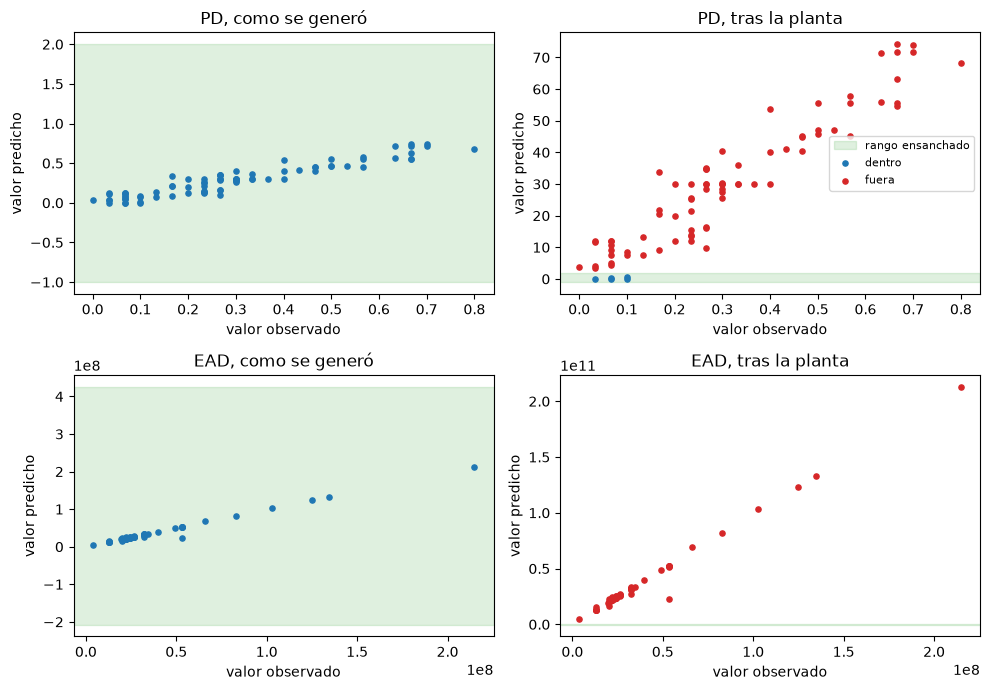

In [19]:
# Dibujar la predicción contra su objetivo antes y después de dos plantas, con el rango ensanchado de la compuerta
# como banda
pairs = [
    ("C01", "german-twin.json", "c01-reliability-bins", 100, [-1, 2], "PD"),
    ("C09", "level-0.json", "c09-ead-backtest", 1000, None, "EAD"),
]
titles = ("como se generó", "tras la planta")
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for row, (case, rel, pair_id, k, band, label) in enumerate(pairs):
    clean = read_json(f"data/derived/{case}/{rel}")
    band = band or widened_range("series", values_at(clean, pair_id)[1])
    for col, document in enumerate((clean, scale(deepcopy(clean), case, k))):
        predicted, observed = (np.array(v) for v in values_at(document, pair_id))
        inside = (predicted >= band[0]) & (predicted <= band[1])
        ax = axes[row, col]
        ax.axhspan(band[0], band[1], color="tab:green", alpha=0.15, label="rango ensanchado")
        ax.scatter(observed[inside], predicted[inside], s=14, color="tab:blue", label="dentro")
        ax.scatter(observed[~inside], predicted[~inside], s=14, color="tab:red", label="fuera")
        ax.set_title(f"{label}, {titles[col]}")
        ax.set_xlabel("valor observado")
        ax.set_ylabel("valor predicho")
axes[0, 1].legend(loc="center right", fontsize=8)
fig.tight_layout()
plt.show()

La fila superior es la PD de C01 contra la tasa de incumplimiento observada de cada tramo, como se generó a la izquierda y en porcentaje a la derecha, con el rango ensanchado $[-1, 2]$ como banda verde. Antes de la planta cada punto es azul y está dentro, con la PD predicha entre 0 y 0,74. Después, los puntos son rojos y llegan a 74, muy por encima de la banda, mientras las tasas observadas no se han movido. La fila inferior es la exposición de C09 contra la exposición realizada en ejes lineales: antes, los puntos siguen la diagonal dentro de la banda; después, las predicciones multiplicadas llenan el gráfico hasta $2\cdot 10^{11}$ y la banda se vuelve una franja fina abajo. La figura muestra lo que ve la compuerta, una nube que salió de la banda. No muestra un defecto que se queda dentro de la banda, que toman la figura siguiente y la sección sobre dónde falla la compuerta.

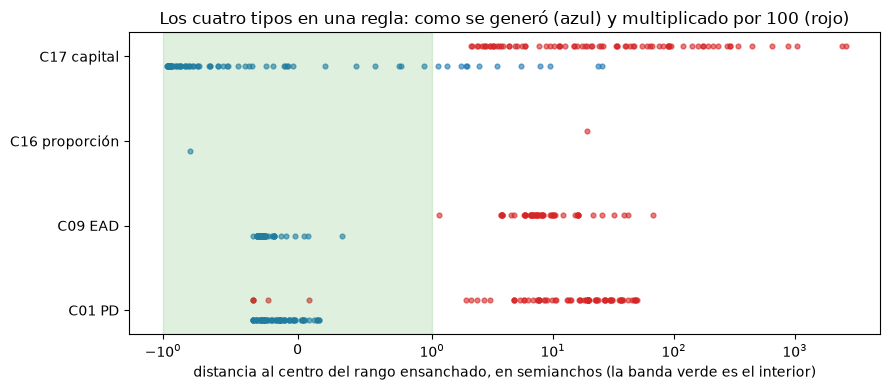

In [20]:
# Poner los cuatro tipos en una regla: cada predicción como distancia al centro de su rango ensanchado, en
# semianchos
pairs_shown = [
    ("C01", "german-twin.json", "c01-reliability-bins", "C01 PD"),
    ("C09", "level-0.json", "c09-ead-backtest", "C09 EAD"),
    ("C16", "fast-run.json", "c16-denominators", "C16 proporción"),
    ("C17", "xi-0-8.json", "c17-capital-quantile", "C17 capital"),
]
fig, ax = plt.subplots(figsize=(9, 4))
for row, (case, rel, pair_id, label) in enumerate(pairs_shown):
    pair = next(p for p in spec[case]["pairs"] if p["id"] == pair_id)
    prediction, target = values_at(read_json(f"data/derived/{case}/{rel}"), pair_id)
    wide = widened_range(pair["kind"], target, pair.get("zero_scale"))
    centre, half = (wide[0] + wide[1]) / 2, (wide[1] - wide[0]) / 2
    for factor, colour in ((1, "tab:blue"), (100, "tab:red")):
        z = [(p * factor - centre) / half for p in prediction if p != 0.0]
        ax.scatter(z, [row + (0.12 if factor == 100 else -0.12)] * len(z), s=12, color=colour, alpha=0.6)
ax.axvspan(-1, 1, color="tab:green", alpha=0.15)
ax.set_xscale("symlog", linthresh=1)
ax.set_yticks(range(len(pairs_shown)))
ax.set_yticklabels([p[3] for p in pairs_shown])
ax.set_xlabel("distancia al centro del rango ensanchado, en semianchos (la banda verde es el interior)")
ax.set_title("Los cuatro tipos en una regla: como se generó (azul) y multiplicado por 100 (rojo)")
fig.tight_layout()
plt.show()

La figura pone los cuatro tipos en una sola regla: cada predicción no nula como su distancia al centro de su rango ensanchado, medida en semianchos, de modo que la banda verde es el interior y todos los tipos son comparables. Los puntos azules, los documentos como se generaron, están dentro de la banda o más allá solo por las estimaciones por encima del doble de la verdad (C17), y los puntos rojos, las mismas predicciones multiplicadas por 100, la dejan: 75 de las 80 PD de C01, las 56 exposiciones de C09 (la más cercana a 1,14 semianchos), la proporción de C16 (a 19,1) y los 80 capitales de C17 (de 2,1 a 2.641 semianchos). El eje logarítmico simétrico hace visible también el punto de la sección siguiente: multiplicar por 100 sale de la banda con amplio margen, y multiplicar por 1,5 no saldría. La figura muestra un solo factor. No muestra el factor con el que cada par empieza a bloquear, lo que mide el barrido.

### Dónde cambia o falla el método

La compuerta pregunta si toda predicción no nula queda fuera de un rango tan ancho como la propia amplitud del objetivo a cada lado. Esa generosidad es deliberada y fija lo que la compuerta puede ver. Esta sección barre un error multiplicativo sobre tres documentos para medir desde dónde empieza a bloquear, pone los umbrales medidos junto a los que enuncia la regla, y luego muestra con código cinco cosas que la compuerta deja pasar. El barrido aplica la función `scale` con factores de 0,001 a 10.000 en 71 pasos logarítmicos al gemelo alemán (ocho métodos juzgados), a la prueba retrospectiva de C09 (un par agrupado) y a C17 (cuatro métodos), y conserva con cada factor la proporción de métodos juzgados que bloquea la compuerta.

In [21]:
# Barrer el factor de 0,001 a 10.000 y guardar, en cada factor, la proporción de métodos juzgados que bloquea la
# compuerta
subjects = {"C01": "german-twin.json", "C09": "level-0.json", "C17": "xi-0-8.json"}
judged = {"C01": 8, "C09": 1, "C17": 4}
factors = np.logspace(-3, 4, 71)


def blocked_methods(case, k):
    planted = scale(deepcopy(read_json(f"data/derived/{case}/{subjects[case]}")), case, float(k))
    return {v["method"] for v in gate.check_document(case, subjects[case], planted, spec).violations}


share = {case: [len(blocked_methods(case, k)) / judged[case] for k in factors] for case in subjects}
below = {case: max(s for s, k in zip(share[case], factors) if k < 1) for case in subjects}
full = {case: round(float(next(k for s, k in zip(share[case], factors) if s == 1.0)), 2) for case in subjects}
print("mayor proporción bloqueada con un factor menor que 1:", below)
print("menor factor de la malla que bloquea a todo método juzgado:", full)

mayor proporción bloqueada con un factor menor que 1: {'C01': 0.0, 'C09': 0.0, 'C17': 0.0}
menor factor de la malla que bloquea a todo método juzgado: {'C01': 3.98, 'C09': 100.0, 'C17': 79.43}


Por debajo de un factor de 1, la mayor proporción bloqueada es 0,0 en los tres documentos: dividir toda predicción por cualquier valor entre 1 y 1.000 nunca se bloquea (las celdas siguientes dicen por qué). Por encima de 1 los tres documentos difieren. Todo método del gemelo alemán se bloquea desde un factor de 3,98 de la malla, todo método de C17 desde 79,43 y la exposición agrupada de C09 desde 100. La malla es gruesa, así que la celda siguiente mide con exactitud el umbral de cinco métodos y lo pone junto al umbral que implica la regla. Para una predicción positiva multiplicada por $k$, la regla del rango bloquea cuando la menor predicción no nula sale del rango por su extremo superior, y la regla del dominio cuando la mayor sale del dominio:

$$k^{*}_{\mathrm{rango}} = \frac{w_{\mathrm{hi}}}{p_{\min}}, \qquad k^{*}_{\mathrm{dominio}} = \frac{d_{\mathrm{hi}}}{p_{\max}}$$

donde $w_{\mathrm{hi}}$ es el extremo superior de $W$ y $p_{\min}$ la menor predicción no nula del método, y $d_{\mathrm{hi}}$ el extremo superior del dominio y $p_{\max}$ la mayor predicción. La bisección siguiente corre la propia compuerta sobre una copia plantada en cada paso.

La celda define la medición: `first_block` biseca el factor entre 1 y $10^{6}$ con 40 divisiones del logaritmo, llamando a la compuerta en cada una, y `stated_threshold` evalúa la ecuación anterior desde el documento. Luego corre ambas para cinco métodos.

In [22]:
# El factor con el que un método empieza a bloquearse: medido por bisección sobre la compuerta y enunciado por la
# regla como ecuación
def first_block(case, method, low=1.0, high=1e6):
    for _ in range(40):
        middle = (low * high) ** 0.5
        low, high = (low, middle) if method in blocked_methods(case, middle) else (middle, high)
    return high


def stated_threshold(case, method):
    document = read_json(f"data/derived/{case}/{subjects[case]}")
    if case == "C01":
        rows = document["outputs"]["rungs"][method]["reliability"]
        return 1.0 / max(r["pd"] for r in rows if r["pd"] is not None)
    if case == "C09":
        predicted, target = values_at(document, "c09-ead-backtest")
        return widened_range("series", target)[1] / min(predicted)
    target = [document["outputs"]["truth"]["annual_loss_quantile"]["value_eur"]]
    own = [v for c in document["outputs"]["cells"] for v in c["capital"][method].get("capital_eur", {}).values()]
    return widened_range("scalar", target)[1] / min(own)


probes = [("C01", "P1-scorecard"), ("C01", "P0-constant"), ("C09", None), ("C17", "sla"), ("C17", "lda_lognormal")]
rows = []
for case, method in probes:
    stated, measured = stated_threshold(case, method), first_block(case, method)
    rows.append(
        {
            "caso": case,
            "método": method or "todos agrupados",
            "enunciado": round(stated, 3),
            "medido": round(measured, 3),
            "brecha relativa": f"{abs(measured / stated - 1):.1e}",
        }
    )
pd.DataFrame(rows)

,caso,método,enunciado,medido,brecha relativa
0,C01,P1-scorecard,1.350,1.350,6.8e-12
1,C01,P0-constant,3.333,3.333,1.1e-11
2,C09,todos agrupados,90.331,90.331,5.9e-12
3,C17,sla,14.760,14.760,7.8e-12
4,C17,lda_lognormal,64.497,64.497,1.2e-11


Los umbrales medido y enunciado coinciden con una brecha relativa de unos $10^{-11}$, que es la tolerancia de la bisección: la tarjeta de puntuación del gemelo alemán se bloquea desde un factor de 1,350 y el control constante desde 3,333, ambos por la regla del dominio (la mayor PD del primero es 0,74 y la del segundo 0,30); la exposición agrupada de C09 desde 90,331; el capital SLA de C17 desde 14,760 y su LDA lognormal desde 64,497, por la regla del rango. Los umbrales difieren mucho entre métodos y casos, de 1,35 a 64,5, y conviene leer por qué. La regla del dominio es la estricta: una PD solo tiene que cruzar 1. La regla del rango necesita que toda predicción cruce el extremo superior, así que decide el método con la menor predicción, relativa al rango del objetivo. La figura siguiente dibuja la proporción bloqueada contra el factor con estos umbrales como líneas punteadas.

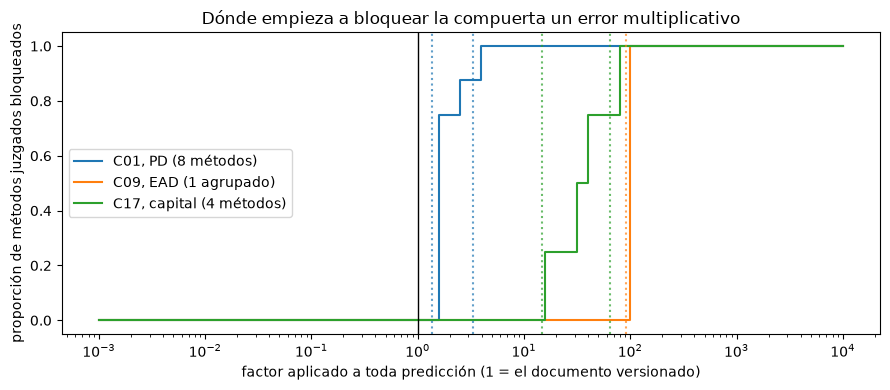

In [23]:
# Dibujar la proporción bloqueada contra el factor, con los umbrales enunciados de la tabla como líneas verticales
# punteadas
fig, ax = plt.subplots(figsize=(9, 4))
colours = {"C01": "tab:blue", "C09": "tab:orange", "C17": "tab:green"}
names = {"C01": "C01, PD (8 métodos)", "C09": "C09, EAD (1 agrupado)", "C17": "C17, capital (4 métodos)"}
for case in subjects:
    ax.step(factors, share[case], where="post", color=colours[case], label=names[case])
for case, method in probes:
    ax.axvline(stated_threshold(case, method), color=colours[case], linestyle=":", alpha=0.7)
ax.axvline(1.0, color="black", linewidth=1)
ax.set_xscale("log")
ax.set_xlabel("factor aplicado a toda predicción (1 = el documento versionado)")
ax.set_ylabel("proporción de métodos juzgados bloqueados")
ax.set_title("Dónde empieza a bloquear la compuerta un error multiplicativo")
ax.legend(loc="center left")
fig.tight_layout()
plt.show()

Cada curva es una escalera: cero hasta su primer umbral y luego un escalón por método hasta que todos están bloqueados, en las líneas punteadas de los umbrales. El gemelo alemán (azul) sube primero, en escalones que agrupan los umbrales de sus ocho métodos, que están entre 1,35 y 3,33, porque su bloqueo es la regla del dominio; C17 (verde) sube entre 14,8 y 64,5, un escalón por método; y C09 (naranja) es un único escalón en 90,3 porque su par agrupa los ocho métodos. Todo lo que queda a la izquierda de la línea negra en 1 es plano en cero. La figura muestra que una PD escrita en porcentaje (un factor de 100) se bloquea en todo método, un capital multiplicado por 1.000 se bloquea en los cuatro y una PD multiplicada por 1,3 no se bloquea. No muestra errores que no son un factor, como un desplazamiento o un cambio de signo, que cubrieron las plantas del paso 7.

El barrido muestra dos puntos ciegos a la vez, y cada uno tiene su celda.

**Un error hacia abajo.** Un capital en miles de euros es el capital dividido por 1.000, no multiplicado. Que la compuerta vea una división depende de si el rango ensanchado llega a cero. Para un observable positivo el extremo inferior de $W$ es $t_{\min} - r\,s$, que es negativo en cuanto la amplitud supera al menor objetivo, y entonces toda predicción positiva, por pequeña que sea, está dentro. La celda siguiente da a la misma función dos objetivos: uno de cuatro valores lejos de cero y otro que empieza cerca de cero.

In [24]:
# Por qué nada se bloquea bajo 1: el rango ensanchado llega a cero en un observable positivo; dar un objetivo lejos
# de cero
def largest_blocking_factor(target, prediction, factors):
    for k in factors:
        if toy_verdict(toy_pair("series", "EUR"), [p * k for p in prediction], target).violations:
            return k
    return None


far = [100.0, 104.0, 108.0, 112.0]
near_zero = [1.0, 40.0, 80.0, 120.0]
down = [0.9, 0.5, 0.1, 0.01, 0.001, 0.0001]
print(
    "objetivo lejos de cero:",
    widened_range("series", far),
    "| mayor factor bajo 1 que bloquea:",
    largest_blocking_factor(far, far, down),
)
print(
    "objetivo que llega cerca de cero:",
    widened_range("series", near_zero),
    "|",
    largest_blocking_factor(near_zero, near_zero, down),
)
print("documento versionado de C09 con factor 1/1000, métodos bloqueados:", len(blocked_methods("C09", 1e-3)))

objetivo lejos de cero: [88.0, 124.0] | mayor factor bajo 1 que bloquea: 0.5
objetivo que llega cerca de cero: [-118.0, 239.0] | None
documento versionado de C09 con factor 1/1000, métodos bloqueados: 0


Para un objetivo de 100 a 112 el rango ensanchado es $[88, 124]$ y la compuerta bloquea una predicción dividida por 2 (un factor de 0,5): todas las predicciones escaladas caen bajo 88. Para un objetivo que empieza en 1 y llega a 120 el rango es $[-118, 239]$ y ningún factor entre 0,9 y 0,0001 se bloquea. Los documentos versionados son el segundo caso: la prueba retrospectiva de C09 con un factor de 1/1.000 bloquea 0 de 1 pares. Un capital o una exposición que abarca una gran parte de su propia escala es por tanto invisible cuando es demasiado pequeño en cualquier factor, que es la forma más común en que aparece un desliz de mil por uno. La tabla muestra la regla trabajando sobre objetivos sintéticos. No dice qué hacer al respecto; la respuesta, en la sección de datos propios, es una unidad declarada en la entrada y una comprobación que trate de unidades y no de rangos.

**Un error dentro del rango tolerado.** La compuerta bloquea solo cuando toda predicción no nula está fuera del rango. La celda siguiente multiplica cada capital de C17 por factores de 1 a 100 y cuenta los métodos bloqueados.

In [25]:
# Un error dentro del rango tolerado es invisible: un método que multiplica su capital por 10 se juzga como el que
# no lo hace
document = read_json("data/derived/C17/xi-0-8.json")
rows = {}
for k in (1.0, 1.5, 2.0, 4.0, 10.0, 20.0, 100.0):
    result = gate.check_document("C17", "xi-0-8.json", scale(deepcopy(document), "C17", k), spec)
    rows[k] = len({v["method"] for v in result.violations})
pd.Series(rows, name="métodos bloqueados").rename_axis("factor sobre todo capital").to_frame().T

factor sobre todo capital,1.0,1.5,2.0,4.0,10.0,20.0,100.0
métodos bloqueados,0,0,0,0,0,1,4


Un método que multiplica su capital por 10 se juzga exactamente igual que el que no: 0 métodos se bloquean con los factores 1, 1,5, 2, 4 y 10, uno con 20 y los cuatro con 100. Esto es el diseño, no un defecto: la regla prohíbe una compuerta de exactitud, porque en el momento en que la compuerta empieza a fallar predicciones inexactas pero honestas se ha vuelto una compuerta de exactitud y será silenciada. Un capital diez veces mayor que la verdad en euros es una mala estimación, y el documento la informa como mala estimación en su propio campo `ratio_to_truth`. La tabla muestra la tolerancia en números. No decide si diez veces es aceptable, lo que no es una cuestión de unidades.

**Un cero exacto.** El cero es el mismo número en toda unidad, así que una predicción exactamente 0 no da evidencia sobre la unidad. La etapa juzga por eso solo las predicciones no nulas, y una respuesta toda en cero no se bloquea. La celda siguiente pone en 0 cada exposición predicha de C09 y luego planta el factor de 1.000 y sobrescribe diez de las 56 con ceros.

In [26]:
# Un cero exacto no aporta evidencia de escala: una respuesta toda en cero es aviso, y un cero junto a un valor en
# otra unidad no oculta nada
document = read_json("data/derived/C09/level-0.json")
all_zero = scale(deepcopy(document), "C09", 0)
mixed = scale(deepcopy(document), "C09", 1000)
for row in ead_rows(mixed)[:10]:
    row["predicted_ead"] = 0.0
variants = [("toda predicción es 0", all_zero), ("10 ceros junto a 46 valores x 1.000", mixed)]
rows = []
for label, variant in variants:
    result = gate.check_document("C09", "level-0.json", variant, spec)
    classes = ", ".join(sorted({v["class"] for v in result.advisories})) or "-"
    rows.append({"variante": label, "bloqueos": len(result.violations), "clases de aviso": classes})
pd.DataFrame(rows)

,variante,bloqueos,clases de aviso
0,toda predicción es 0,0,degenerate_constant_prediction
1,10 ceros junto a 46 valores x 1.000,1,-


Una respuesta que es cero en todas partes no se bloquea: pasa con el aviso `degenerate_constant_prediction`, pues una constante sobre un objetivo que varía se registra y nunca se rechaza. Y los diez ceros junto a 46 valores multiplicados por 1.000 no ocultan nada: las predicciones no nulas están todas fuera del rango, así que el par se bloquea una vez. Un cero no es evidencia a favor de la unidad, y tampoco en contra. La tabla muestra ambos desenlaces. No muestra que un método que predice 0 para un observable que tiene escala es un método que no predice nada, lo que el aviso dice en palabras y la compuerta deja al lector.

**Un par acotado solo por su dominio.** Un par de cota no se compara con ningún objetivo, así que lo único que puede decir de él la compuerta es si sale de su dominio. Una tendencia central escalada de una cartera de bajo incumplimiento es una PD menor que 0,01 en todas partes, y una PD escrita en porcentaje menor que 0,01 vuelve a ser una probabilidad. La celda siguiente toma la cartera simulada de C05 y multiplica la tendencia central por 1, 100, 500 y 1.000.

In [27]:
# Un par acotado solo por su dominio declarado: una tendencia central bajo 0,01 escrita en porcentaje sigue siendo
# una probabilidad válida
document = read_json("data/derived/C05/ldp-sim-1.json")
central = [v for row in document["outputs"]["bounds"]["scaled_central_tendency"] for v in row["pd"]]
print("mayor valor de la tendencia central escalada:", round(max(central), 5))
print("factor con el que sale del dominio [0, 1]:", round(1 / max(central), 1))
rows = []
for k in (1, 100, 500, 1000):
    planted = deepcopy(document)
    for row in planted["outputs"]["bounds"]["scaled_central_tendency"]:
        row["pd"] = [v * k for v in row["pd"]]
    blocked = len(gate.check_document("C05", "ldp-sim-1.json", planted, spec).violations)
    rows.append({"factor": k, "mayor valor": round(max(central) * k, 3), "bloqueos": blocked})
pd.DataFrame(rows)

mayor valor de la tendencia central escalada: 0.00196
factor con el que sale del dominio [0, 1]: 509.1


,factor,mayor valor,bloqueos
0,1,0.002,0
1,100,0.196,0
2,500,0.982,0
3,1000,1.964,1


La mayor PD de tendencia central del documento es 0,00196, así que el factor que sale de $[0, 1]$ es 509,1. Los factores 1, 100 y 500 pasan, con un mayor valor de 0,002, 0,196 y 0,982, y solo 1.000 se bloquea, con 1,964. Una PD escrita en porcentaje, que es el factor de 100, es aquí una probabilidad perfectamente válida de 0,196 y ninguna regla sobre unidades puede verla. El diseño de la funcionalidad registra el mismo límite para este par. La tabla muestra el factor con el que una cota empieza a bloquear. No muestra qué haría un lector para hacer más seguro un par así: declararle un objetivo, lo que la especificación no puede hacer cuando no existe una verdad.

**Una predicción faltante, y una ruta que no encuentra nada.** Una predicción nula es un valor faltante, un método que no tiene valor allí y lo dice, así que se cuenta y nunca se rechaza. Una ruta que no se resuelve en nada es otra cosa, una especificación que ya no coincide con su documento, y es un error. La celda siguiente planta cinco nulos, todos nulos y un documento con todo el bloque del backtest borrado.

In [28]:
# Una predicción faltante es aviso y una ruta que no encuentra nada es error: la compuerta nunca pasa lo que no
# puede leer
document = read_json("data/derived/C09/level-0.json")
some_null, all_null, renamed = deepcopy(document), deepcopy(document), deepcopy(document)
for row in ead_rows(some_null)[:5]:
    row["predicted_ead"] = None
for row in ead_rows(all_null):
    row["predicted_ead"] = None
del renamed["outputs"]["ead_backtest"]
rows = []
for label, variant in [("5 predicciones nulas", some_null), ("toda predicción nula", all_null)]:
    result = gate.check_document("C09", "level-0.json", variant, spec)
    rows.append(
        {"variante": label, "bloqueos": len(result.violations), "qué dice": result.advisories[0]["detail"][:80]}
    )
try:
    gate.check_document("C09", "level-0.json", renamed, spec)
except gate.UnitGateError as refusal:
    rows.append(
        {
            "variante": "falta el bloque de la prueba retrospectiva",
            "bloqueos": "UnitGateError",
            "qué dice": str(refusal)[:80],
        }
    )
pd.DataFrame(rows)

,variante,bloqueos,qué dice
0,5 predicciones nulas,0,c09-ead-backtest: 5 of 56 predictions are null...
1,toda predicción nula,0,c09-ead-backtest: 56 of 56 predictions are nul...
2,falta el bloque de la prueba retrospectiva,UnitGateError,pair 'c09-ead-backtest': the prediction path '...


Cinco nulos dan el aviso `5 of 56 predictions are null (missing, not checked)`, y 56 nulos dan `56 of 56`: ninguno bloquea, y un documento cuyas predicciones son todas nulas pasa la compuerta sin que se juzgue ninguna unidad. El bloque borrado lanza `UnitGateError` con el par, el papel (la predicción), la ruta y el documento, así que un par que no encuentra nada nunca es un pase. De ello se siguen dos cosas. Un pase de la compuerta es un pase sobre las predicciones que pudo leer, y la cuenta de avisos es parte del veredicto: quien mira solo el número de violaciones bloqueantes pierde un documento sin nada que juzgar. Y la compuerta no puede distinguir un método que legítimamente no tiene valor de uno cuyo valor se perdió; el documento lo dice, en sus propias razones de nulo. La tabla lista los tres casos. La sección siguiente aplica la compuerta a un archivo que no está en el repositorio.

### Úsalo con tus propios datos

La compuerta lee un documento (un diccionario leído de JSON) y un par que dice dónde están su predicción y su objetivo. Para usarla sobre un archivo propio necesitas tres cosas: el documento con la forma de las rutas del par, el par declarado en la especificación con su tipo, su unidad y, para un observable acotado, el dominio y la razón, y un identificador de caso para la entrada. La celda siguiente construye, en el notebook, un marco pequeño que representa tu archivo: 40 préstamos con una exposición realizada en dólares estadounidenses y un pronóstico de ella en tres versiones, en dólares, en centavos (un factor de 100) y en miles de dólares (dividido por 1.000). Declara el par con el tipo `series`, la unidad `USD` y el dominio $[0, \infty)$, y valida la especificación antes de leer ningún documento.

In [29]:
# Un archivo propio, construido aquí como un marco pequeño: un pronóstico de exposición en USD, en centavos y en
# miles, junto a desenlaces en USD
rng = np.random.default_rng(7)
my_loans = pd.DataFrame({"loan": range(1, 41), "realised_usd": rng.lognormal(mean=11.5, sigma=0.5, size=40).round(0)})
my_loans["forecast_usd"] = (my_loans["realised_usd"] * rng.normal(1.0, 0.15, size=40)).round(0)
my_loans["forecast_cents"] = my_loans["forecast_usd"] * 100
my_loans["forecast_kusd"] = (my_loans["forecast_usd"] / 1000).round(2)
note = "Una exposición es un monto no negativo por definición."
my_pair = {
    "id": "my-ead",
    "file": "my-loans.json",
    "prediction": "rows[].forecast",
    "target": "rows[].realised",
    "kind": "series",
    "unit": "USD",
    "domain": [0, None],
    "domain_reason": note,
}
my_spec = {"C99": {"pairs": [my_pair]}}
gate.validate_spec(my_spec)
print("préstamos:", len(my_loans), "| mediana realizada:", f"{my_loans['realised_usd'].median():,.0f} USD")
print(
    "mediana del pronóstico en USD, centavos y miles de USD:",
    my_loans[["forecast_usd", "forecast_cents", "forecast_kusd"]].median().round(0).tolist(),
)

préstamos: 40 | mediana realizada: 82,356 USD
mediana del pronóstico en USD, centavos y miles de USD: [86824.0, 8682400.0, 87.0]


El marco tiene 40 préstamos con una exposición realizada mediana de 82.356 dólares estadounidenses, y las medianas de las tres columnas del pronóstico son 86.824, 8.682.400 y 87: el mismo pronóstico en tres unidades. La especificación se validó sin error, que es lo primero que hay que leer: un par mal formado se detiene aquí. La celda siguiente construye el documento que lee el par, `{"rows": [{"forecast": ..., "realised": ...}]}` (las rutas del par son `rows[].forecast` y `rows[].realised`), y juzga cada columna.

In [30]:
# Construir el documento que lee el par desde el marco y correr la compuerta con la columna en USD, en centavos y en
# miles
def loans_document(frame, forecast_column):
    return {
        "rows": [
            {"forecast": float(f), "realised": float(r)} for f, r in zip(frame[forecast_column], frame["realised_usd"])
        ]
    }


rows = []
for column in ("forecast_usd", "forecast_cents", "forecast_kusd"):
    result = gate.check_document("C99", "my-loans.json", loans_document(my_loans, column), my_spec)
    classes = ", ".join(sorted({v["class"] for v in result.violations})) or "-"
    rows.append(
        {
            "columna del pronóstico": column,
            "pares comprobados": result.pairs_checked,
            "bloqueos": len(result.violations),
            "clase": classes,
        }
    )
pd.DataFrame(rows)

,columna del pronóstico,pares comprobados,bloqueos,clase
0,forecast_usd,1,0,-
1,forecast_cents,1,1,prediction_outside_observable
2,forecast_kusd,1,0,-


El pronóstico en dólares pasa con un par comprobado y ninguna violación. El pronóstico en centavos se bloquea por `prediction_outside_observable`: los 40 valores quedan muy por encima del rango ensanchado. El pronóstico en miles pasa, exactamente como predijo la sección hacia abajo: las exposiciones realizadas van de decenas de miles a unos pocos cientos de miles de dólares, su rango ensanchado empieza bajo cero y un pronóstico de 87 queda dentro. Esta es la lección más útil para tus propios datos. La compuerta detectó el factor de 100 y no detectó el factor de 1/1.000 sobre el mismo archivo, así que un pase dice que el pronóstico no es demasiado grande en un factor amplio, nunca que esté en la unidad correcta. Lo que hay que revisar en la salida de una corrida sobre tus datos es por tanto la cuenta de pares comprobados (cero significa que el patrón no alcanzó ningún documento), las violaciones bloqueantes con su clase y su mensaje, y los avisos; y lo que hay que añadir a mano es una declaración de la unidad en el propio archivo, que la compuerta no lee. La última celda muestra qué dice el validador sobre los tres errores al escribir un par.

In [31]:
# Un par mal formado se rechaza antes de leer ningún documento: tres errores que nombra el validador
bad = {
    "un dominio sin su razón": {k: v for k, v in my_pair.items() if k != "domain_reason"},
    "una serie sin su objetivo": {k: v for k, v in my_pair.items() if k != "target"},
    "un campo que la compuerta no conoce": {**my_pair, "tolerance": 0.1},
}
rows = []
for label, pair in bad.items():
    try:
        gate.validate_pair(pair)
        said = "aceptado"
    except gate.UnitGateError as refusal:
        said = str(refusal)
    rows.append({"error": label, "el validador dice": said})
pd.DataFrame(rows)

,error,el validador dice
0,un dominio sin su razón,pair 'my-ead': a 'domain' needs its 'domain_re...
1,una serie sin su objetivo,pair 'my-ead': kind 'series' needs its 'target...
2,un campo que la compuerta no conoce,pair 'my-ead': unknown field(s) ['tolerance']


Un dominio sin su razón, una serie sin su objetivo y un campo que la compuerta no conoce se rechazan, cada uno con una frase que nombra el par y la regla, antes de leer ningún documento. Los rechazos son las comprobaciones propias de la especificación: un dominio necesita su razón de una frase, una serie necesita la ruta de su objetivo y no se acepta ningún campo fuera de la lista de la etapa. Son la razón para escribir un par en la especificación y no en código. Para que la comprobación sea parte de tu propia corrida, pon el par en tu copia de la especificación bajo un identificador de caso y corre la comprobación distribuida, `python scripts/check_units.py`, que además informa un patrón que no alcanza ningún archivo y una carpeta de caso sin entrada.

## Resultados

**Respuesta:** Un número correcto en su propia unidad y erróneo en la unidad de la pregunta lo ve la compuerta cuando sale de un rango tan ancho como la propia amplitud del objetivo a cada lado, o sale del dominio declarado de un observable acotado. Sobre los documentos versionados la compuerta juzgó 8 pares de 4 casos y no bloqueó ninguno, y cada error plantado se bloqueó: una PD en porcentaje 13 veces, una exposición multiplicada por 1.000 una vez, y los cambios de signo de una exposición y de un capital. Los umbrales se miden, no se suponen: una PD empieza a bloquear con un factor de 1,350 (la regla del dominio), la exposición agrupada de C09 con 90,331 y el capital SLA de C17 con 14,760, iguales a las ecuaciones $d_{\mathrm{hi}}/p_{\max}$ y $w_{\mathrm{hi}}/p_{\min}$ con una brecha relativa de $10^{-11}$. Lo que deja pasar es un error dentro del rango (un capital multiplicado por 10), un error hacia abajo (0 métodos bloqueados con un factor de 1/1.000, un pronóstico en miles que pasa), un cero exacto, una cota que es solo un dominio (una PD en porcentaje de 0,196) y una predicción faltante.

- **Fallo.** Una PD de 22, un capital de 163.483.000 contra 163.483 y una constante de 1,00 contra 433 a 484 se bloquean cada una; el AUC del motor es 0,7566 para la PD como se generó, en porcentaje y dividida por 10, y sus pruebas de calibración rechazan el porcentaje y ponen en rojo la PD dividida.
- **Regla.** Cuatro tipos de objetivo con sus rangos ensanchados: $[-1, 2]$ para 80 PD binarias, $[-207.327.763,\ 425.928.805]$ para las 56 exposiciones, $[0, 1{,}7]$ para una proporción de 0,85 y $[0, 3{,}27\cdot 10^{8}]$ para el capital de C17, del que 68 de 80 cuantiles están dentro.
- **Especificación.** 21 casos, 53 pares, 21 dominios en los tipos que estiman y 14 en las cotas, 9 escalas del cero.
- **Dónde falla.** No se bloquea: un factor de 10 sobre un capital, cualquier factor menor que 1 en los documentos versionados, un cero, una tendencia central en porcentaje y un nulo.
- **Tus datos.** Un pronóstico en centavos se bloquea y el mismo pronóstico en miles pasa: añade la unidad al archivo y lee los avisos.

Lo que este notebook no hace: no juzga la exactitud, no corre la comprobación dentro del horneado, que está planificada para la versión siguiente, y planta solo errores de escala y de signo.

## Resumen

- Una compuerta que pregunta si la cadena de cálculo corrió no puede ver una respuesta en la unidad equivocada: el AUC del motor es 0,7566 para una PD como se generó, en porcentaje y dividida por 10, y solo las pruebas que leen la probabilidad rechazan el porcentaje.
- La etapa `unit_gate` ensancha un objetivo por su propia amplitud a cada lado (una serie), por el dominio de la etiqueta (un desenlace 0/1, $[-1, 2]$), por su propio valor absoluto (una verdad conocida) o en absoluto (una cota), bloquea un par cuyas predicciones no nulas quedan todas fuera, o alguna de cuyas predicciones sale de un dominio declarado o no es finita, y solo registra un nulo o una predicción constante.
- La especificación guarda 21 casos y 53 pares como dato, validado antes de usarse; la compuerta juzgó 8 pares en cuatro documentos versionados y no bloqueó ninguno, y bloqueó cada planta: un porcentaje 13 veces, un factor de 1.000, dos cambios de signo.
- Un error multiplicativo empieza a bloquear en un umbral que fija la regla, $w_{\mathrm{hi}}/p_{\min}$ o $d_{\mathrm{hi}}/p_{\max}$, medido aquí de 1,350 a 90,331, y los valores medidos igualan las ecuaciones con una brecha relativa de $10^{-11}$.
- Deja pasar un error dentro del rango, cualquier error hacia abajo en un observable cuyo rango llega a cero, un cero exacto, una cota dentro de su dominio y un nulo; un pase nunca es una afirmación de que la unidad sea correcta.
- En la versión 1.01.000 la compuerta juzga los documentos versionados, en integración continua y antes de un despliegue; la comprobación dentro del horneado está planificada para la versión siguiente.

**Qué probar a continuación.** Planta un cambio de signo en la proporción de C16 y una exposición dividida por 100 en C09 y lee ambos veredictos; luego declara un par para un archivo propio con un `domain` y corre `scripts/check_units.py` sobre una copia de la especificación. Continúa con el notebook 07, que compara los métodos del producto sobre un mismo protocolo.

## Referencias

- Mavin, A., Wilkinson, P., Harwood, A. y Novak, M. (2009), Easy Approach to Requirements Syntax (EARS), la forma en que se escriben los requisitos de la compuerta de unidades, RE'09. https://doi.org/10.1109/RE.2009.9
- Comité de Basilea, Marco de Basilea, CRE32, el enfoque IRB (la PD como insumo y su piso), tal como lo cita el documento de diseño. https://www.bis.org/committees/bcbs/basel-framework/standard/cre/32/inforce/2023-01-01/published/2020-03-27
- Comité de Basilea (2023), Report on the 2023 banking turmoil, la fuente de la proporción observada de depósitos del caso C16. https://www.bis.org/bcbs/publ/d555.htm
- Comité de Basilea (2016), Standardised Measurement Approach for operational risk, documento de consulta, la referencia del capital del caso C17. https://www.bis.org/bcbs/publ/d355.htm
- Hofmann, H. (1994), Statlog (German Credit Data), UCI Machine Learning Repository (CC BY 4.0). https://archive.ics.uci.edu/dataset/144/statlog+german+credit+data
- BCE (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk. https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- riskvalidation 1.1.0, la versión del motor que fijan los notebooks. https://pypi.org/project/riskvalidation/1.1.0/
- Este repositorio: `data-pipeline/pipeline/stages/unit_gate.py`, `data-pipeline/config/unit_pairs.json`, `scripts/check_units.py`, `docs/design/features/units/` y `tests/test_unit_gate.py`.